In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# Project paths
PROJECT_ROOT = Path.cwd().parent
OUTPUT_DIR = PROJECT_ROOT / "outputs"
DATA_PATH = OUTPUT_DIR / "heatguard_cleaned.csv"

# Load the cleaned dataset from Member 1
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("File:", DATA_PATH)
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
File: c:\HeatGuard\outputs\heatguard_cleaned.csv
Dataset shape: (4555, 38)

First 5 rows:


,patient_day_id,city,date,air_temp_c,rh_pct,wind_kmh,solar_wm2,rain_last_24h_mm,pm25_ugm3,ozone_ppb,...,dizziness,nausea,wbgt_mean_v2_c,wbgt_max_v2_c,wbgt_min_v2_c,temperature_max_v2_c,shortwave_mean_v2_wm2,shortwave_max_v2_wm2,elevation_v2_m,heat_event_risk
0,HD100976,Ahmedabad,2024-05-17,40.25,27.9,8.0,NaN,0.0,58.9,50.8,...,0.0,0.0,28.354917,33.538,23.697,41.8,313.750000,961.0,53.0,0
1,HD107746,Jaipur,2024-05-09,39.61,33.5,14.4,309.8,0.0,52.6,46.2,...,0.0,0.0,27.156167,32.239,22.854,41.0,318.875000,972.0,431.0,0
2,HD100257,Mumbai,2024-06-20,28.63,89.4,16.0,35.1,4.0,44.9,30.4,...,0.0,0.0,27.675000,30.029,25.967,30.1,120.916667,358.0,6.0,0
3,HD107922,Ahmedabad,2024-05-13,36.91,45.9,10.6,NaN,0.0,54.9,48.5,...,0.0,0.0,28.992500,39.629,23.549,39.4,280.541667,952.0,53.0,0
4,HD110666,Ahmedabad,2024-05-20,39.20,27.8,13.1,NaN,0.0,53.3,50.2,...,0.0,0.0,28.321792,33.779,23.776,42.7,289.666667,926.0,53.0,0


In [2]:
# Verify the target column and inspect class distribution.

TARGET = "heat_event_risk"

print("Target column exists:", TARGET in df.columns)
print("\nDataset dimensions:", df.shape)
print("\nTarget data type:", df[TARGET].dtype)
print("\nMissing target values:", df[TARGET].isna().sum())

print("\nTarget class counts:")
display(df[TARGET].value_counts().sort_index().rename("count").to_frame())

print("\nTarget class percentages:")
display(
    (df[TARGET].value_counts(normalize=True).sort_index() * 100)
    .round(2)
    .rename("percentage")
    .to_frame()
)

Target column exists: True

Dataset dimensions: (4555, 38)

Target data type: int64

Missing target values: 0

Target class counts:


,count
heat_event_risk,
0,4334
1,221



Target class percentages:


,percentage
heat_event_risk,
0,95.15
1,4.85


In [5]:
# Separate the target, identifiers, and input features.

TARGET = "heat_event_risk"

EXCLUDED_COLUMNS = [
    "patient_day_id",
    "date",
    TARGET
]

X = df.drop(columns=EXCLUDED_COLUMNS).copy()
y = df[TARGET].copy()

# Identify numerical and categorical features.
NUMERIC_FEATURES = X.select_dtypes(
    include=["number"]
).columns.tolist()

CATEGORICAL_FEATURES = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nNumerical features:", len(NUMERIC_FEATURES))
print(NUMERIC_FEATURES)

print("\nCategorical features:", len(CATEGORICAL_FEATURES))
print(CATEGORICAL_FEATURES)

print("\nTotal features:", len(NUMERIC_FEATURES) + len(CATEGORICAL_FEATURES))

Feature matrix shape: (4555, 35)
Target vector shape: (4555,)

Numerical features: 32
['air_temp_c', 'rh_pct', 'wind_kmh', 'solar_wm2', 'rain_last_24h_mm', 'pm25_ugm3', 'ozone_ppb', 'no2_ppb', 'night_min_c', 'estimated_wbgt', 'cumulative_heat_3d', 'age', 'pregnant', 'chronic_condition', 'heart_disease', 'diabetes', 'ckd', 'diuretic', 'beta_blocker', 'outdoor_work', 'hydration_score', 'acclimatized', 'headache', 'dizziness', 'nausea', 'wbgt_mean_v2_c', 'wbgt_max_v2_c', 'wbgt_min_v2_c', 'temperature_max_v2_c', 'shortwave_mean_v2_wm2', 'shortwave_max_v2_wm2', 'elevation_v2_m']

Categorical features: 3
['city', 'gender', 'exertion_level']

Total features: 35


In [6]:
# Check whether patient-day IDs repeat in the cleaned dataset.

id_counts = df["patient_day_id"].value_counts()

repeated_ids = id_counts[id_counts > 1]

print("Total records:", len(df))
print("Unique patient-day IDs:", df["patient_day_id"].nunique())
print("IDs appearing more than once:", len(repeated_ids))
print("Records belonging to repeated IDs:", int(repeated_ids.sum()))

if len(repeated_ids) > 0:
    print("\nRepeated ID frequency:")
    display(repeated_ids.value_counts().sort_index().rename_axis(
        "records_per_ID"
    ).to_frame("number_of_IDs"))

    print("\nSample repeated IDs and their target labels:")
    display(
        df[df["patient_day_id"].isin(repeated_ids.index)]
        [["patient_day_id", "heat_event_risk"]]
        .sort_values("patient_day_id")
        .head(12)
    )

Total records: 4555
Unique patient-day IDs: 4528
IDs appearing more than once: 27
Records belonging to repeated IDs: 54

Repeated ID frequency:


,number_of_IDs
records_per_ID,
2,27



Sample repeated IDs and their target labels:


,patient_day_id,heat_event_risk
1108,HD100052,0
2835,HD100052,0
1735,HD100229,0
2697,HD100229,0
2604,HD100885,0
3405,HD100885,0
2984,HD101575,0
3864,HD101575,0
1219,HD101683,0
3168,HD101683,0


In [7]:
# Check whether duplicate IDs have consistent target labels.

repeated_records = df[
    df["patient_day_id"].isin(repeated_ids.index)
].copy()

label_counts_per_id = (
    repeated_records.groupby("patient_day_id")["heat_event_risk"]
    .nunique()
)

conflicting_ids = label_counts_per_id[label_counts_per_id > 1]

print("Repeated IDs checked:", len(repeated_ids))
print("IDs with conflicting target labels:", len(conflicting_ids))

if len(conflicting_ids) > 0:
    print("\nIDs requiring investigation:")
    display(
        repeated_records[
            repeated_records["patient_day_id"].isin(conflicting_ids.index)
        ].sort_values("patient_day_id")
    )
else:
    print("All repeated IDs have consistent target labels.")

Repeated IDs checked: 27
IDs with conflicting target labels: 0
All repeated IDs have consistent target labels.


In [8]:
from sklearn.model_selection import GroupShuffleSplit

# Keep all records sharing a patient-day ID in the same split.
groups = df["patient_day_id"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

train_ids = set(groups.iloc[train_idx])
test_ids = set(groups.iloc[test_idx])

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training positive cases:", int(y_train.sum()))
print("Testing positive cases:", int(y_test.sum()))
print("Training positive rate (%):", round(y_train.mean() * 100, 2))
print("Testing positive rate (%):", round(y_test.mean() * 100, 2))
print("IDs shared across train and test:", len(train_ids & test_ids))

Training feature shape: (3643, 35)
Testing feature shape: (912, 35)
Training positive cases: 179
Testing positive cases: 42
Training positive rate (%): 4.91
Testing positive rate (%): 4.61
IDs shared across train and test: 0


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical features: fill missing values with training-set medians,
# then scale them for Logistic Regression.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical features: fill missing values with the most frequent
# training-set category, then convert categories into numeric columns.
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate preprocessing to each feature type.
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES)
])

print("Preprocessing pipeline created.")
print("Numeric features:", len(NUMERIC_FEATURES))
print("Categorical features:", len(CATEGORICAL_FEATURES))
print("Numeric missing-value strategy: median")
print("Categorical missing-value strategy: most frequent")
print("Categorical encoding: one-hot encoding")
print("Numeric scaling: StandardScaler")

Preprocessing pipeline created.
Numeric features: 32
Categorical features: 3
Numeric missing-value strategy: median
Categorical missing-value strategy: most frequent
Categorical encoding: one-hot encoding
Numeric scaling: StandardScaler


In [ ]:
from sklearn.linear_model import LogisticRegression

# Combine preprocessing and the classifier into one pipeline.
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# Fit using training data only.
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")
print("Training records:", len(X_train))
print("Test records kept separate:", len(X_test))
print("Class weighting: balanced")


Logistic Regression trained successfully!
Training records: 3643
Test records kept separate: 912
Class weighting: balanced


In [11]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Predict class labels and positive-class probabilities.
y_pred_lr = logistic_model.predict(X_test)
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

# Classification metrics.
print("LOGISTIC REGRESSION — TEST SET EVALUATION")
print("=" * 45)

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred_lr,
    labels=[0, 1],
    target_names=["No heat-risk event", "Heat-risk event"],
    zero_division=0
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_lr, labels=[0, 1]))

print("\nROC-AUC:", round(roc_auc_score(y_test, y_prob_lr), 4))
print("PR-AUC (Average Precision):",
      round(average_precision_score(y_test, y_prob_lr), 4))

LOGISTIC REGRESSION — TEST SET EVALUATION

Classification report:
                    precision    recall  f1-score   support

No heat-risk event       0.97      0.75      0.85       870
   Heat-risk event       0.10      0.55      0.16        42

          accuracy                           0.74       912
         macro avg       0.53      0.65      0.50       912
      weighted avg       0.93      0.74      0.81       912


Confusion matrix:
[[652 218]
 [ 19  23]]

ROC-AUC: 0.6867
PR-AUC (Average Precision): 0.1574


In [12]:
from sklearn.ensemble import RandomForestClassifier

# Build the Random Forest pipeline.
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced_subsample",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Train on training data only.
random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")
print("Number of trees:", 300)
print("Class weighting: balanced_subsample")
print("Training records:", len(X_train))
print("Test records kept separate:", len(X_test))

Random Forest trained successfully!
Number of trees: 300
Class weighting: balanced_subsample
Training records: 3643
Test records kept separate: 912


In [13]:
# Predict test-set labels and probabilities.
y_pred_rf = random_forest_model.predict(X_test)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("RANDOM FOREST — TEST SET EVALUATION")
print("=" * 42)

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred_rf,
    labels=[0, 1],
    target_names=["No heat-risk event", "Heat-risk event"],
    zero_division=0
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_rf, labels=[0, 1]))

print("\nROC-AUC:", round(roc_auc_score(y_test, y_prob_rf), 4))
print("PR-AUC (Average Precision):",
      round(average_precision_score(y_test, y_prob_rf), 4))

RANDOM FOREST — TEST SET EVALUATION

Classification report:
                    precision    recall  f1-score   support

No heat-risk event       0.95      1.00      0.98       870
   Heat-risk event       1.00      0.02      0.05        42

          accuracy                           0.96       912
         macro avg       0.98      0.51      0.51       912
      weighted avg       0.96      0.96      0.93       912


Confusion matrix:
[[870   0]
 [ 41   1]]

ROC-AUC: 0.6924
PR-AUC (Average Precision): 0.199


In [14]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import precision_score, recall_score, f1_score

# Generate out-of-fold probabilities using training data only.
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_prob_lr = np.zeros(len(X_train), dtype=float)

for fold, (fit_idx, val_idx) in enumerate(
    cv.split(X_train, y_train, groups=groups.iloc[train_idx]), start=1
):
    fold_model = clone(logistic_model)

    fold_model.fit(
        X_train.iloc[fit_idx],
        y_train.iloc[fit_idx]
    )

    oof_prob_lr[val_idx] = fold_model.predict_proba(
        X_train.iloc[val_idx]
    )[:, 1]

print("Out-of-fold predictions generated.")
print("Training records evaluated out-of-fold:", len(oof_prob_lr))
print("Positive cases in training:", int(y_train.sum()))

# Compare several possible thresholds on these training-only predictions.
threshold_rows = []

for threshold in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:
    pred = (oof_prob_lr >= threshold).astype(int)

    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_train, pred, zero_division=0),
        "recall": recall_score(y_train, pred, zero_division=0),
        "f1": f1_score(y_train, pred, zero_division=0),
        "predicted_positive": int(pred.sum())
    })

threshold_results = pd.DataFrame(threshold_rows)

display(
    threshold_results.round(3)
)

Out-of-fold predictions generated.
Training records evaluated out-of-fold: 3643
Positive cases in training: 179


,threshold,precision,recall,f1,predicted_positive
0,0.10,0.052,0.983,0.098,3401
1,0.15,0.055,0.961,0.104,3138
2,0.20,0.058,0.927,0.109,2858
3,0.25,0.059,0.827,0.110,2521
4,0.30,0.064,0.777,0.119,2160
5,0.40,0.082,0.676,0.146,1482
6,0.50,0.101,0.542,0.171,958


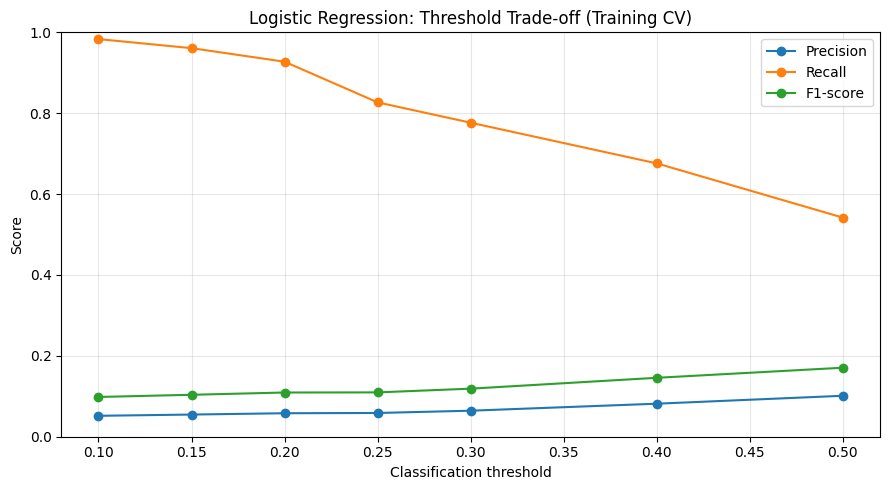

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_results["threshold"],
    threshold_results["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["f1"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Classification threshold")
plt.ylabel("Score")
plt.title("Logistic Regression: Threshold Trade-off (Training CV)")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

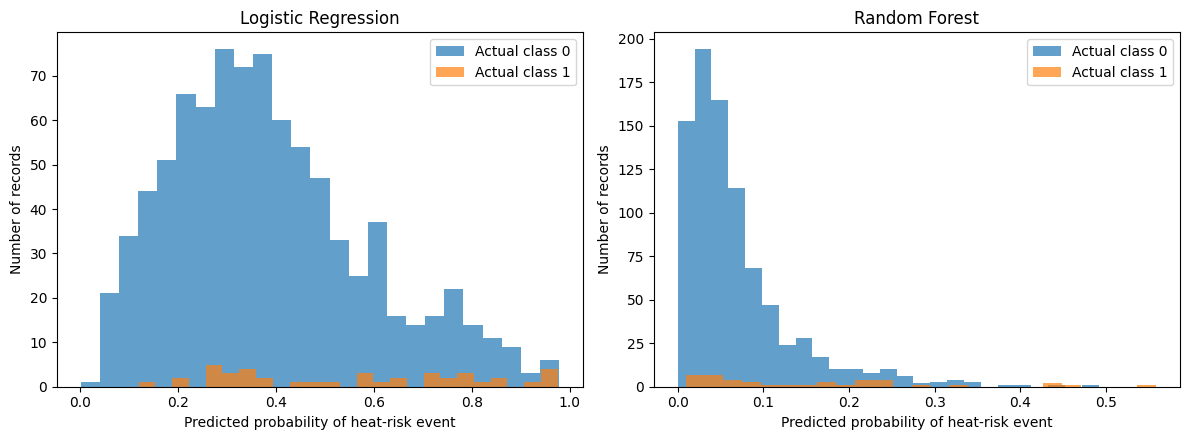

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Logistic Regression probabilities
axes[0].hist(
    y_prob_lr[y_test == 0],
    bins=25,
    alpha=0.7,
    label="Actual class 0"
)
axes[0].hist(
    y_prob_lr[y_test == 1],
    bins=25,
    alpha=0.7,
    label="Actual class 1"
)
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted probability of heat-risk event")
axes[0].set_ylabel("Number of records")
axes[0].legend()

# Random Forest probabilities
axes[1].hist(
    y_prob_rf[y_test == 0],
    bins=25,
    alpha=0.7,
    label="Actual class 0"
)
axes[1].hist(
    y_prob_rf[y_test == 1],
    bins=25,
    alpha=0.7,
    label="Actual class 1"
)
axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predicted probability of heat-risk event")
axes[1].set_ylabel("Number of records")
axes[1].legend()

plt.tight_layout()
plt.show()

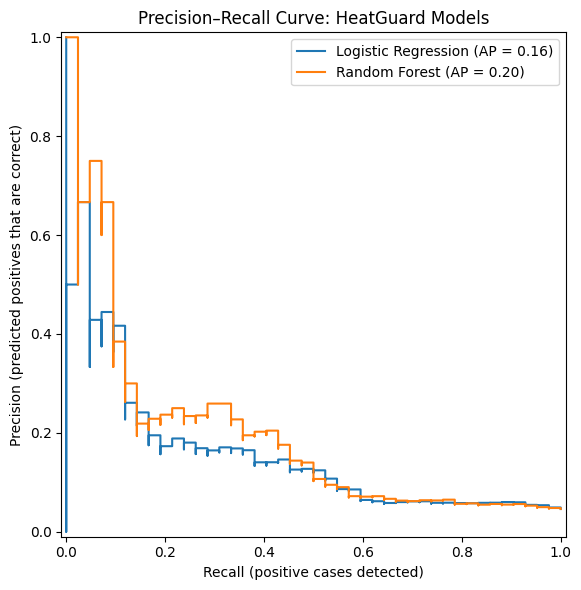

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(8, 6))

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob_lr,
    name="Logistic Regression",
    ax=ax
)

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob_rf,
    name="Random Forest",
    ax=ax
)

ax.set_title("Precision–Recall Curve: HeatGuard Models")
ax.set_xlabel("Recall (positive cases detected)")
ax.set_ylabel("Precision (predicted positives that are correct)")
ax.legend()
plt.tight_layout()
plt.show()

In [19]:
model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "ROC-AUC": roc_auc_score(y_test, y_prob_lr),
        "PR-AUC (AP)": average_precision_score(y_test, y_prob_lr),
        "Recall at 0.5": recall_score(y_test, y_pred_lr),
        "Precision at 0.5": precision_score(
            y_test, y_pred_lr, zero_division=0
        )
    },
    {
        "Model": "Random Forest",
        "ROC-AUC": roc_auc_score(y_test, y_prob_rf),
        "PR-AUC (AP)": average_precision_score(y_test, y_prob_rf),
        "Recall at 0.5": recall_score(y_test, y_pred_rf),
        "Precision at 0.5": precision_score(
            y_test, y_pred_rf, zero_division=0
        )
    }
])

display(model_comparison.round(3))

,Model,ROC-AUC,PR-AUC (AP),Recall at 0.5,Precision at 0.5
0,Logistic Regression,0.687,0.157,0.548,0.095
1,Random Forest,0.692,0.199,0.024,1.000


In [20]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score

lr_importance = permutation_importance(
    logistic_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

rf_importance = permutation_importance(
    random_forest_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

print("Permutation importance calculated for both models.")

Permutation importance calculated for both models.


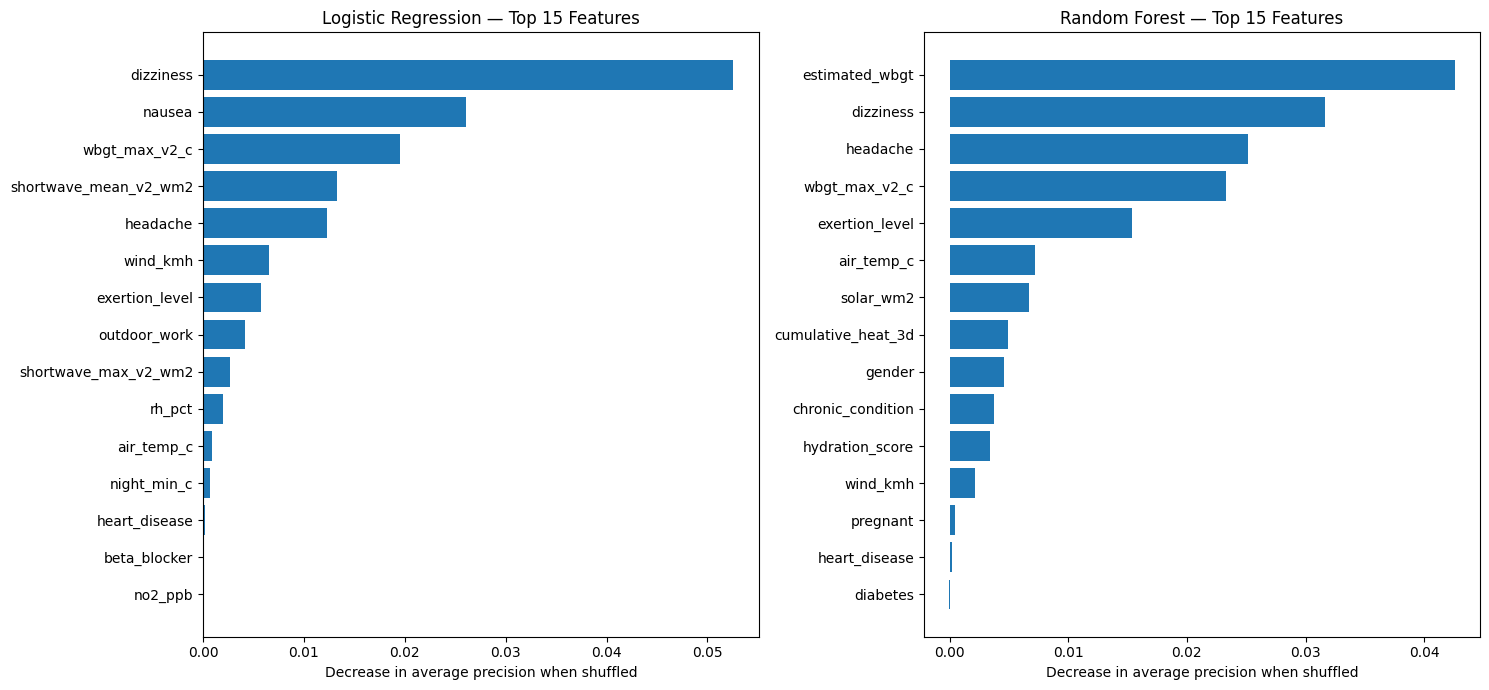

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

lr_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": lr_importance.importances_mean
}).sort_values("Importance", ascending=False)

rf_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": rf_importance.importances_mean
}).sort_values("Importance", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

lr_top = lr_importance_df.head(15).sort_values("Importance")
rf_top = rf_importance_df.head(15).sort_values("Importance")

axes[0].barh(lr_top["Feature"], lr_top["Importance"])
axes[0].set_title("Logistic Regression — Top 15 Features")
axes[0].set_xlabel("Decrease in average precision when shuffled")

axes[1].barh(rf_top["Feature"], rf_top["Importance"])
axes[1].set_title("Random Forest — Top 15 Features")
axes[1].set_xlabel("Decrease in average precision when shuffled")

plt.tight_layout()
plt.show()

In [24]:
for col in df.columns:
    if any(word in col.lower() for word in [
        "shortwave", "dizziness", "nausea", "headache",
        "wbgt", "exertion", "heat_event_risk"
    ]):
        print(col)

estimated_wbgt
exertion_level
headache
dizziness
nausea
wbgt_mean_v2_c
wbgt_max_v2_c
wbgt_min_v2_c
shortwave_mean_v2_wm2
shortwave_max_v2_wm2
heat_event_risk


In [25]:
important_features = [
    "dizziness",
    "nausea",
    "headache",
    "wbgt_max_v2_c",
    "shortwave_mean_v2_wm2",
    "estimated_wbgt",
    "exertion_level",
    "heat_event_risk"
]

display(df[important_features].head(10))

,dizziness,nausea,headache,wbgt_max_v2_c,shortwave_mean_v2_wm2,estimated_wbgt,exertion_level,heat_event_risk
0,0.0,0.0,0.0,33.538,313.750000,32.09,High,0
1,0.0,0.0,0.0,32.239,318.875000,30.56,Moderate,0
2,0.0,0.0,0.0,30.029,120.916667,28.82,High,0
3,0.0,0.0,NaN,39.629,280.541667,34.95,Low,0
4,0.0,0.0,0.0,33.779,289.666667,31.14,Low,0
5,0.0,0.0,NaN,31.277,182.250000,30.43,Low,0
6,0.0,0.0,0.0,34.372,260.416667,31.35,Moderate,0
7,0.0,0.0,0.0,30.166,132.541667,29.86,Low,0
8,NaN,0.0,0.0,32.989,284.625000,32.82,High,0
9,0.0,0.0,0.0,28.428,332.125000,26.90,Low,0


In [26]:
print("Missing target values:", df["heat_event_risk"].isna().sum())
print("\nTarget class counts:")
print(df["heat_event_risk"].value_counts(dropna=False))

print("\nSymptom values by target:")
display(
    df.groupby("heat_event_risk")[
        ["dizziness", "nausea", "headache"]
    ].agg(["mean", "count"]).round(3)
)

Missing target values: 0

Target class counts:
heat_event_risk
0    4334
1     221
Name: count, dtype: int64

Symptom values by target:


dizziness       nausea       headache      
                     mean count   mean count     mean count
heat_event_risk                                            
0                   0.049  4246  0.028  4249    0.072  4245
1                   0.266   218  0.130   215    0.252   218

In [27]:
for symptom in ["dizziness", "nausea", "headache"]:
    print(f"\n{symptom.upper()}")

    display(
        pd.crosstab(
            df[symptom].fillna("Missing"),
            df["heat_event_risk"],
            normalize="index"
        ).round(3)
    )


DIZZINESS


heat_event_risk,0,1
dizziness,,
0.0,0.962,0.038
1.0,0.782,0.218
Missing,0.967,0.033



NAUSEA


heat_event_risk,0,1
nausea,,
0.0,0.957,0.043
1.0,0.807,0.193
Missing,0.934,0.066



HEADACHE


heat_event_risk,0,1
headache,,
0.0,0.960,0.040
1.0,0.848,0.152
Missing,0.967,0.033


In [29]:
# Apply the fitted preprocessing steps to the test data
X_test_transformed = logistic_model.named_steps[
    "preprocessor"
].transform(X_test)

# Get feature names after one-hot encoding
transformed_feature_names = logistic_model.named_steps[
    "preprocessor"
].get_feature_names_out()

print("Transformed test shape:", X_test_transformed.shape)
print("Number of transformed features:", len(transformed_feature_names))
print("\nFirst 15 transformed feature names:")
print(transformed_feature_names[:15])

Transformed test shape: (912, 48)
Number of transformed features: 48

First 15 transformed feature names:
['numeric__air_temp_c' 'numeric__rh_pct' 'numeric__wind_kmh'
 'numeric__solar_wm2' 'numeric__rain_last_24h_mm' 'numeric__pm25_ugm3'
 'numeric__ozone_ppb' 'numeric__no2_ppb' 'numeric__night_min_c'
 'numeric__estimated_wbgt' 'numeric__cumulative_heat_3d' 'numeric__age'
 'numeric__pregnant' 'numeric__chronic_condition' 'numeric__heart_disease']


In [30]:
import shap

# Extract the trained logistic regression classifier
lr_classifier = logistic_model.named_steps["classifier"]

# Use a sample of transformed training data as the background
X_train_transformed = logistic_model.named_steps[
    "preprocessor"
].transform(X_train)

background = shap.sample(
    X_train_transformed,
    min(100, X_train_transformed.shape[0]),
    random_state=42
)

# Create the SHAP explainer
lr_explainer = shap.LinearExplainer(
    lr_classifier,
    background
)

# Explain the transformed test data
lr_shap_values = lr_explainer(X_test_transformed)

print("SHAP values shape:", lr_shap_values.values.shape)
print("SHAP explanation created successfully.")

SHAP values shape: (912, 48)
SHAP explanation created successfully.


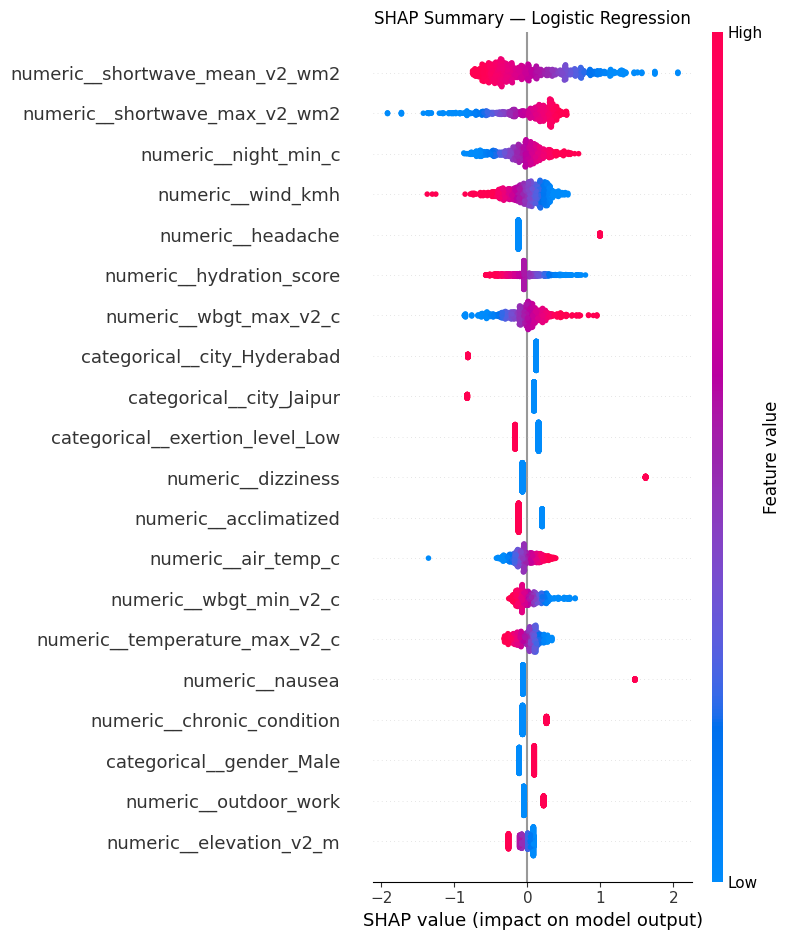

In [31]:
import matplotlib.pyplot as plt

shap.summary_plot(
    lr_shap_values.values,
    X_test_transformed,
    feature_names=transformed_feature_names,
    max_display=20,
    show=False
)

plt.title("SHAP Summary — Logistic Regression")
plt.tight_layout()
plt.show()

Top 15 features by mean absolute SHAP:


,Feature,Mean absolute SHAP
29,numeric__shortwave_mean_v2_wm2,0.4601
30,numeric__shortwave_max_v2_wm2,0.3273
8,numeric__night_min_c,0.2270
2,numeric__wind_kmh,0.2116
22,numeric__headache,0.1995
20,numeric__hydration_score,0.1958
26,numeric__wbgt_max_v2_c,0.1907
36,categorical__city_Hyderabad,0.1900
37,categorical__city_Jaipur,0.1748
46,categorical__exertion_level_Low,0.1602


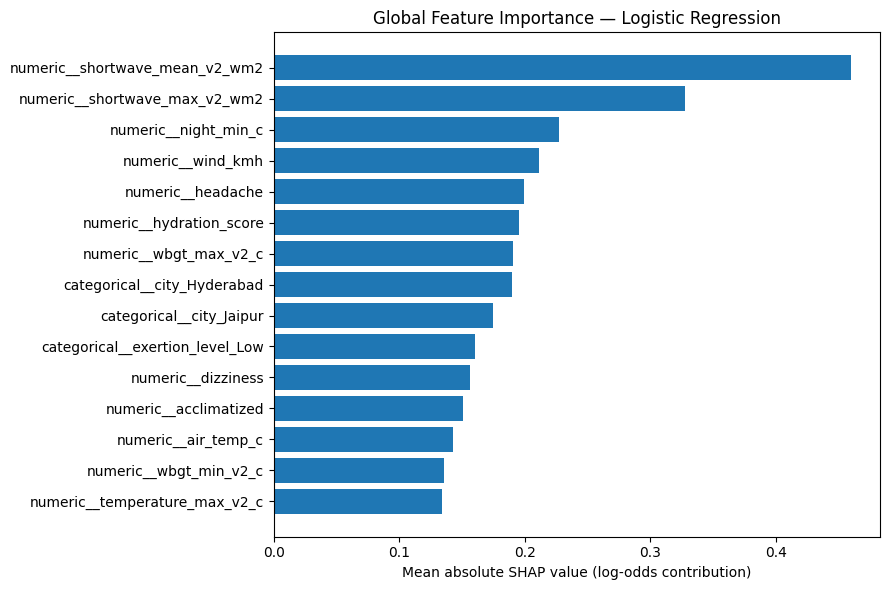

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Mean absolute SHAP value for each transformed feature
shap_importance_df = pd.DataFrame({
    "Feature": transformed_feature_names,
    "Mean absolute SHAP": np.abs(lr_shap_values.values).mean(axis=0)
}).sort_values("Mean absolute SHAP", ascending=False)

print("Top 15 features by mean absolute SHAP:")
display(shap_importance_df.head(15).round(4))

# Plot the top 15
top_shap = shap_importance_df.head(15).sort_values("Mean absolute SHAP")

plt.figure(figsize=(9, 6))
plt.barh(top_shap["Feature"], top_shap["Mean absolute SHAP"])
plt.xlabel("Mean absolute SHAP value (log-odds contribution)")
plt.title("Global Feature Importance — Logistic Regression")
plt.tight_layout()
plt.show()

In [33]:
# Find the positive test record with the highest Logistic Regression score
positive_positions = np.flatnonzero(y_test.to_numpy() == 1)
best_positive_position = positive_positions[
    np.argmax(y_prob_lr[positive_positions])
]

print("Test-set row position:", best_positive_position)
print("Actual target:", y_test.iloc[best_positive_position])
print("Predicted risk probability:", round(
    float(y_prob_lr[best_positive_position]), 4
))

print("\nOriginal feature values:")
display(X_test.iloc[[best_positive_position]].T)

Test-set row position: 479
Actual target: 1
Predicted risk probability: 0.9756

Original feature values:


,2352
city,Hyderabad
air_temp_c,35.75
rh_pct,47.2
wind_kmh,6.4
solar_wm2,382.5
rain_last_24h_mm,1.4
pm25_ugm3,44.6
ozone_ppb,48.6
no2_ppb,30.3
night_min_c,25.27


In [34]:
# SHAP explanation for the selected positive test record
local_shap = lr_shap_values[best_positive_position]

local_shap_df = pd.DataFrame({
    "Feature": transformed_feature_names,
    "SHAP value": local_shap.values
})

# Largest positive contributions
positive_contributions = (
    local_shap_df[local_shap_df["SHAP value"] > 0]
    .sort_values("SHAP value", ascending=False)
    .head(10)
)

# Largest negative contributions
negative_contributions = (
    local_shap_df[local_shap_df["SHAP value"] < 0]
    .sort_values("SHAP value", ascending=True)
    .head(10)
)

print("Top features pushing the prediction toward HIGHER risk:")
display(positive_contributions.round(4))

print("\nTop features pushing the prediction toward LOWER risk:")
display(negative_contributions.round(4))

Top features pushing the prediction toward HIGHER risk:


,Feature,SHAP value
23,numeric__dizziness,1.6196
24,numeric__nausea,1.4723
22,numeric__headache,0.9950
29,numeric__shortwave_mean_v2_wm2,0.7316
2,numeric__wind_kmh,0.2922
19,numeric__outdoor_work,0.2229
21,numeric__acclimatized,0.2032
46,categorical__exertion_level_Low,0.1543
26,numeric__wbgt_max_v2_c,0.1053
42,categorical__gender_Male,0.0947



Top features pushing the prediction toward LOWER risk:


,Feature,SHAP value
36,categorical__city_Hyderabad,-0.8143
20,numeric__hydration_score,-0.3895
30,numeric__shortwave_max_v2_wm2,-0.2598
8,numeric__night_min_c,-0.1821
31,numeric__elevation_v2_m,-0.1046
13,numeric__chronic_condition,-0.0655
41,categorical__gender_Female,-0.0643
28,numeric__temperature_max_v2_c,-0.0396
33,categorical__city_Bengaluru,-0.0348
38,categorical__city_Kolkata,-0.0330


In [35]:
row_transformed = X_test_transformed[best_positive_position]

encoding_check = pd.DataFrame({
    "Feature": transformed_feature_names,
    "Encoded value": np.asarray(row_transformed).ravel()
})

display(
    encoding_check[
        encoding_check["Feature"].str.contains(
            "exertion_level|city_|gender_"
        )
    ]
)

,Feature,Encoded value
32,categorical__city_Ahmedabad,0.0
33,categorical__city_Bengaluru,0.0
34,categorical__city_Chennai,0.0
35,categorical__city_Delhi,0.0
36,categorical__city_Hyderabad,1.0
37,categorical__city_Jaipur,0.0
38,categorical__city_Kolkata,0.0
39,categorical__city_Lucknow,0.0
40,categorical__city_Mumbai,0.0
41,categorical__gender_Female,0.0


In [36]:
exertion_check = encoding_check[
    encoding_check["Feature"].str.contains("exertion_level")
].copy()

exertion_check["SHAP value"] = [
    local_shap.values[
        list(transformed_feature_names).index(feature)
    ]
    for feature in exertion_check["Feature"]
]

display(exertion_check.round(4))

,Feature,Encoded value,SHAP value
45,categorical__exertion_level_High,1.0,0.0697
46,categorical__exertion_level_Low,0.0,0.1543
47,categorical__exertion_level_Moderate,0.0,0.0165


In [37]:
shap_probability = lr_shap_values.base_values[best_positive_position]
shap_log_odds = shap_probability + local_shap.values.sum()
reconstructed_probability = 1 / (1 + np.exp(-shap_log_odds))

print(f"SHAP base value: {shap_probability:.4f}")
print(f"Sum of SHAP contributions: {local_shap.values.sum():.4f}")
print(f"Reconstructed probability: {reconstructed_probability:.4%}")
print(f"Actual model probability: {y_prob_lr[best_positive_position]:.4%}")

SHAP base value: -0.4489
Sum of SHAP contributions: 4.1393
Reconstructed probability: 97.5646%
Actual model probability: 97.5646%


## Model Findings and Limitations

### 1. Model Performance

Two classification models were evaluated: Logistic Regression and Random Forest. Both showed some ability to distinguish between the two target classes, but performance on the minority class (`heat_event_risk = 1`) remained limited.

* **Logistic Regression:** ROC-AUC = 0.687, PR-AUC = 0.157, recall = 0.548 at the default threshold of 0.5.
* **Random Forest:** ROC-AUC = 0.692, PR-AUC = 0.199, recall = 0.024 at the default threshold of 0.5.

Random Forest achieved better ranking metrics, but its default classification threshold identified only 1 of the 42 positive test records. Logistic Regression identified 23 of 42, but generated many false positives. Accuracy alone is therefore insufficient for evaluating these imbalanced data.

### 2. Model Explainability

Permutation importance and SHAP were used to investigate which features influenced model predictions. Radiation-related variables, nighttime minimum temperature, wind speed, hydration, and reported symptoms appeared among the influential features.

For an individual positive test record, the Logistic Regression model predicted a probability of approximately 97.56%. Its SHAP contributions reconstructed the same probability, confirming the numerical consistency of the local explanation.

These explanations describe model behaviour and feature associations; they do not establish causal relationships.

### 3. Limitations

* The target labels have not been clinically validated.
* The positive class is underrepresented, which makes reliable detection challenging.
* The models produce false positives and false negatives, and their probability calibration has not been established.
* Some data-quality concerns remain, including suspicious zero values and possible inconsistencies in cumulative heat exposure.
* Symptom variables may introduce target leakage if they were recorded after the heat-risk event.
* Evaluation used a single group-aware train/test split; performance should be checked using further validation before drawing strong conclusions.

### 4. Conclusion

The current models demonstrate a preliminary machine-learning workflow for exploring heat-event risk, including preprocessing, imbalanced classification, evaluation, and explainability. The results are not sufficient for clinical or operational deployment. Further data validation, leakage checks, model improvement, and independent evaluation are required before the predictions can be considered reliable.


In [38]:
MODEL_DIR = PROJECT_ROOT / "models"

print("Model directory:", MODEL_DIR)
print("Directory exists:", MODEL_DIR.exists())

if MODEL_DIR.exists():
    for file in MODEL_DIR.iterdir():
        print(file.name, "-", f"{file.stat().st_size:,} bytes")

Model directory: c:\HeatGuard\models
Directory exists: False


In [39]:
import joblib

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

lr_model_path = MODEL_DIR / "heatguard_logistic_regression.pkl"
joblib.dump(logistic_model, lr_model_path)

print("Model saved successfully:", lr_model_path)
print("File exists:", lr_model_path.exists())

Model saved successfully: c:\HeatGuard\models\heatguard_logistic_regression.pkl
File exists: True


In [84]:
from sklearn.base import clone
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score,
    f1_score, average_precision_score, roc_auc_score
)

# Use the existing fitted pipeline as the template
lr_experiment = clone(lr)
lr_experiment.set_params(classifier__C=0.1)

# Fit on training data only
lr_experiment.fit(X_train, y_train)

# Evaluate at the default threshold
probs = lr_experiment.predict_proba(X_test)[:, 1]
preds = (probs >= 0.5).astype(int)

print("EXPERIMENT: Logistic Regression, C=0.1")
print("Confusion matrix:\n", confusion_matrix(y_test, preds))
print(f"Precision: {precision_score(y_test, preds, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test, preds, zero_division=0):.3f}")
print(f"F1-score:  {f1_score(y_test, preds, zero_division=0):.3f}")
print(f"PR-AUC:    {average_precision_score(y_test, probs):.3f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, probs):.3f}")

EXPERIMENT: Logistic Regression, C=0.1
Confusion matrix:
 [[662 208]
 [ 19  23]]
Precision: 0.100
Recall:    0.548
F1-score:  0.168
PR-AUC:    0.162
ROC-AUC:   0.689


In [90]:
print("Available dataframe variables:")
for name, obj in list(globals().items()):
    if hasattr(obj, "columns") and hasattr(obj, "shape"):
        print(name, obj.shape, list(obj.columns[:5]))

print("\nGroup variable candidates:")
for name, obj in list(globals().items()):
    if name.lower() in ["groups_train", "train_groups", "group_train", "patient_day_id"]:
        print(name, type(obj), getattr(obj, "shape", None))

Available dataframe variables:
df (4555, 38) ['patient_day_id', 'city', 'date', 'air_temp_c', 'rh_pct']
X (4555, 35) ['city', 'air_temp_c', 'rh_pct', 'wind_kmh', 'solar_wm2']
repeated_records (54, 38) ['patient_day_id', 'city', 'date', 'air_temp_c', 'rh_pct']
X_train (3643, 35) ['city', 'air_temp_c', 'rh_pct', 'wind_kmh', 'solar_wm2']
X_test (912, 35) ['city', 'air_temp_c', 'rh_pct', 'wind_kmh', 'solar_wm2']
model_comparison (2, 5) ['Model', 'ROC-AUC', 'PR-AUC (AP)', 'Recall at 0.5', 'Precision at 0.5']
lr_importance_df (35, 2) ['Feature', 'Importance']
rf_importance_df (35, 2) ['Feature', 'Importance']
lr_top (15, 2) ['Feature', 'Importance']
rf_top (15, 2) ['Feature', 'Importance']
shap_importance_df (48, 2) ['Feature', 'Mean absolute SHAP']
top_shap (15, 2) ['Feature', 'Mean absolute SHAP']
local_shap_df (48, 2) ['Feature', 'SHAP value']
positive_contributions (10, 2) ['Feature', 'SHAP value']
negative_contributions (10, 2) ['Feature', 'SHAP value']
encoding_check (48, 2) ['Feature'

In [91]:
import numpy as np
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

oof_probs = cross_val_predict(
    clone(lr),
    X_train,
    y_train,
    cv=cv,
    groups=train_groups,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

threshold_results = []

for threshold in np.arange(0.05, 0.51, 0.05):
    predictions = (oof_probs >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_train, predictions, zero_division=0),
        "Recall": recall_score(y_train, predictions, zero_division=0),
        "F1-score": f1_score(y_train, predictions, zero_division=0),
        "Predicted positives": int(predictions.sum())
    })

lr_cv_threshold_table = pd.DataFrame(threshold_results)
display(lr_cv_threshold_table.round(3))

,Threshold,Precision,Recall,F1-score,Predicted positives
0,0.05,0.050,0.989,0.094,3574
1,0.10,0.052,0.983,0.098,3401
2,0.15,0.055,0.961,0.104,3138
3,0.20,0.058,0.927,0.109,2858
4,0.25,0.059,0.827,0.110,2521
5,0.30,0.064,0.777,0.119,2160
6,0.35,0.072,0.726,0.130,1818
7,0.40,0.082,0.676,0.146,1482
8,0.45,0.093,0.615,0.161,1186
9,0.50,0.101,0.542,0.171,958


In [92]:
print(lr_cv_threshold_table.to_string(index=False))

 Threshold  Precision   Recall  F1-score  Predicted positives
      0.05   0.049524 0.988827  0.094325                 3574
      0.10   0.051749 0.983240  0.098324                 3401
      0.15   0.054812 0.960894  0.103708                 3138
      0.20   0.058083 0.927374  0.109318                 2858
      0.25   0.058707 0.826816  0.109630                 2521
      0.30   0.064352 0.776536  0.118854                 2160
      0.35   0.071507 0.726257  0.130195                 1818
      0.40   0.081646 0.675978  0.145695                 1482
      0.45   0.092749 0.614525  0.161172                 1186
      0.50   0.101253 0.541899  0.170624                  958


In [93]:
from pathlib import Path

app_path = Path(r"C:\HeatGuard\api\app.py")
print(app_path.read_text(encoding="utf-8"))


from fastapi import FastAPI

app = FastAPI(
    title="HeatGuard API",
    description="API for AI-assisted personalized heat-risk prediction.",
    version="1.0.0"
)


@app.get("/")
def home():
    return {
        "message": "HeatGuard API is running",
        "status": "healthy"
    }


In [94]:
from pathlib import Path

model_path = Path(r"C:\HeatGuard\models\heatguard_logistic_regression.pkl")

print("Model exists:", model_path.exists())
print("Model size:", f"{model_path.stat().st_size:,} bytes" if model_path.exists() else "Not found")

Model exists: True
Model size: 7,338 bytes


In [98]:

from pathlib import Path

import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

app = FastAPI(
    title="HeatGuard API",
    description="API for AI-assisted personalized heat-risk prediction.",
    version="1.0.0",
)

MODEL_PATH = (
    Path(r"C:\HeatGuard\models\heatguard_logistic_regression.pkl")
)

model = joblib.load(MODEL_PATH)


class HeatRiskInput(BaseModel):
    city: str
    air_temp_c: float = Field(ge=-20, le=60)
    rh_pct: float = Field(ge=0, le=100)
    wind_kmh: float = Field(ge=0, le=250)
    solar_wm2: float = Field(ge=0, le=1500)
    rain_last_24h_mm: float = Field(ge=0)
    pm25_ugm3: float = Field(ge=0)
    ozone_ppb: float = Field(ge=0)
    no2_ppb: float = Field(ge=0)
    night_min_c: float = Field(ge=-30, le=50)
    estimated_wbgt: float = Field(ge=-20, le=60)
    cumulative_heat_3d: float = Field(ge=0)
    age: float = Field(ge=0, le=120)
    gender: str
    pregnant: int = Field(ge=0, le=1)
    chronic_condition: int = Field(ge=0, le=1)
    heart_disease: int = Field(ge=0, le=1)
    diabetes: int = Field(ge=0, le=1)
    ckd: int = Field(ge=0, le=1)
    diuretic: int = Field(ge=0, le=1)
    beta_blocker: int = Field(ge=0, le=1)
    outdoor_work: int = Field(ge=0, le=1)
    exertion_level: str
    hydration_score: float = Field(ge=0, le=1)
    acclimatized: int = Field(ge=0, le=1)
    headache: int = Field(ge=0, le=1)
    dizziness: int = Field(ge=0, le=1)
    nausea: int = Field(ge=0, le=1)
    wbgt_mean_v2_c: float
    wbgt_max_v2_c: float
    wbgt_min_v2_c: float
    temperature_max_v2_c: float
    shortwave_mean_v2_wm2: float
    shortwave_max_v2_wm2: float
    elevation_v2_m: float


@app.get("/")
def home():
    return {
        "message": "HeatGuard API is running",
        "status": "healthy",
    }


@app.get("/health")
def health():
    return {
        "status": "healthy",
        "model_loaded": model is not None,
    }


@app.post("/predict")
def predict(data: HeatRiskInput):
    try:
        input_df = pd.DataFrame([data.model_dump()])
        risk_score = float(model.predict_proba(input_df)[0][1])

        if risk_score < 0.30:
            risk_level = "Low"
        elif risk_score < 0.60:
            risk_level = "Moderate"
        else:
            risk_level = "High"

        return {
            "estimated_risk_score": round(risk_score * 100, 2),
            "risk_level": risk_level,
            "disclaimer": (
                "Experimental model output, not a clinical diagnosis "
                "or a validated medical risk assessment."
            ),
        }
    except Exception as exc:
        raise HTTPException(
            status_code=500,
            detail=f"Prediction failed: {str(exc)}",
        ) from exc


In [99]:
import joblib

model = joblib.load(MODEL_PATH)

print("Model loaded successfully:", type(model).__name__)
print("Expected input features:", len(model.feature_names_in_))
print("First five features:", list(model.feature_names_in_[:5]))

Model loaded successfully: Pipeline
Expected input features: 35
First five features: ['city', 'air_temp_c', 'rh_pct', 'wind_kmh', 'solar_wm2']


In [101]:
import json

sample = df.drop(
    columns=["heat_event_risk", "patient_day_id", "date"]
).iloc[0]

payload = sample.astype(object).where(sample.notna(), None).to_dict()

print(json.dumps(payload, indent=2, allow_nan=False))

{
  "city": "Ahmedabad",
  "air_temp_c": 40.25,
  "rh_pct": 27.9,
  "wind_kmh": 8.0,
  "solar_wm2": null,
  "rain_last_24h_mm": 0.0,
  "pm25_ugm3": 58.9,
  "ozone_ppb": 50.8,
  "no2_ppb": 31.8,
  "night_min_c": 28.48,
  "estimated_wbgt": 32.09,
  "cumulative_heat_3d": 42.74,
  "age": 29.0,
  "gender": "Female",
  "pregnant": 0.0,
  "chronic_condition": 0.0,
  "heart_disease": 0.0,
  "diabetes": 0.0,
  "ckd": 0.0,
  "diuretic": 0.0,
  "beta_blocker": 0.0,
  "outdoor_work": 0.0,
  "exertion_level": "High",
  "hydration_score": null,
  "acclimatized": 1.0,
  "headache": 0.0,
  "dizziness": 0.0,
  "nausea": 0.0,
  "wbgt_mean_v2_c": 28.354916666666668,
  "wbgt_max_v2_c": 33.538,
  "wbgt_min_v2_c": 23.697,
  "temperature_max_v2_c": 41.8,
  "shortwave_mean_v2_wm2": 313.75,
  "shortwave_max_v2_wm2": 961.0,
  "elevation_v2_m": 53.0
}
